# BÀI TẬP THỰC HÀNH 2


## Sử dụng thư viện nào hãy import ở trên đây

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf
from statsmodels.graphics import tsaplots


## BÀI 1: KHÁM PHÁ DỮ LIỆU (EDA)
**Dataset sử dụng:** Dataset 1 - Monthly Retail Sales (`a10.csv`)
- Mô tả: Doanh số bán lẻ dược phẩm theo tháng (Australia / US Monthly Sales), từ 07/1991 đến 06/2008..
- Nguồn dữ liệu: https://raw.githubusercontent.com/selva86/datasedf/master/a10.csv

### 1. Tải và đọc dữ liệu

In [3]:
url = "https://raw.githubusercontent.com/selva86/datasets/master/a10.csv"
df = pd.read_csv(url)

# Xem vài dòng đầu
print("Kích thước dữ liệu:", df.shape)
print("\nTên cột:", df.columns.tolist())
display(df.head())
display(df.tail())

Kích thước dữ liệu: (204, 2)

Tên cột: ['date', 'value']


,date,value
0,1991-07-01,3.526591
1,1991-08-01,3.180891
2,1991-09-01,3.252221
3,1991-10-01,3.611003
4,1991-11-01,3.565869


,date,value
199,2008-02-01,21.654285
200,2008-03-01,18.264945
201,2008-04-01,23.107677
202,2008-05-01,22.912510
203,2008-06-01,19.431740


### 2. Chuyển cột date thành chỉ số thời gian
Chuyển `date` sang kiểu ngày tháng, sau đó đặt làm index

In [4]:
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")

display(df.head())
print("Kiểu index:", type(df.index).__name__)
print("Khoảng thời gian:", df.index.min(), "đến", df.index.max())
print("Số quan sát hợp lệ:", len(df))
print("Tần suất thời gian ước tính: hàng tháng")

,value
date,
1991-07-01,3.526591
1991-08-01,3.180891
1991-09-01,3.252221
1991-10-01,3.611003
1991-11-01,3.565869


Kiểu index: DatetimeIndex
Khoảng thời gian: 1991-07-01 00:00:00 đến 2008-06-01 00:00:00
Số quan sát hợp lệ: 204
Tần suất thời gian ước tính: hàng tháng


### Mô tả dataset

In [5]:
df.describe()

,value
count,204.000000
mean,10.694430
std,5.956998
min,2.814520
25%,5.844095
50%,9.319345
75%,14.289964
max,29.665356


### 3. Vẽ đồ thị chuỗi thời gian

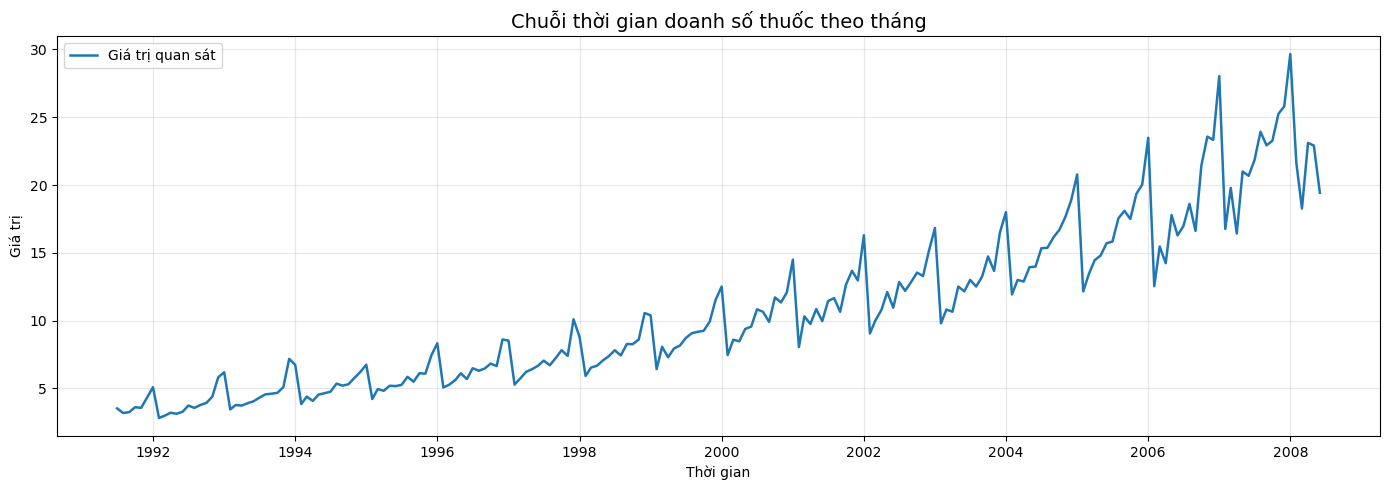

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))


ax.plot(df.index, df["value"], linewidth=1.8, label="Giá trị quan sát")
ax.set_title("Chuỗi thời gian doanh số thuốc theo tháng", fontsize=14)
ax.set_xlabel("Thời gian")
ax.set_ylabel("Giá trị")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Trả lời câu hỏi số 1

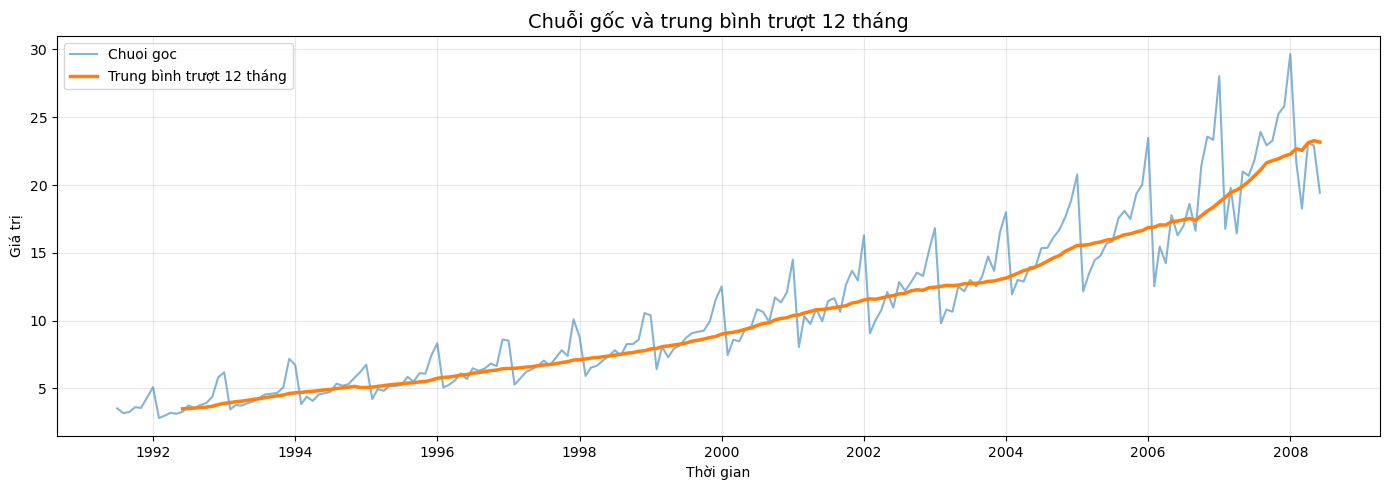

In [ ]:
# Tính trung bình trượt 12 tháng với window=12 là 12 quan sát
rolling_12 = df["value"].rolling(window=12, min_periods=12).mean()

# Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df["value"], alpha=0.55, label="Chuoi goc")
ax.plot(rolling_12.index, rolling_12, linewidth=2.5, label="Trung bình trượt 12 tháng")
ax.set_title("Chuỗi gốc và trung bình trượt 12 tháng", fontsize=14)
ax.set_xlabel("Thời gian")
ax.set_ylabel("Giá trị")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Trả lời câu hỏi số 2

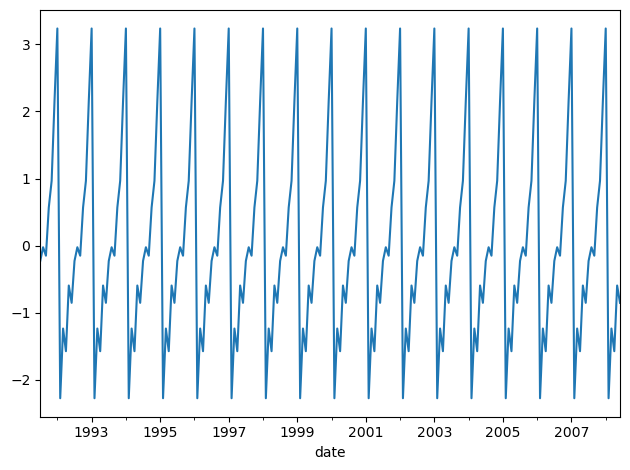

In [21]:

decomposition = seasonal_decompose(df["value"], model="additive", period=12)
fig = decomposition.seasonal.plot()
plt.tight_layout()
plt.show()

### Trả lời câu hỏi số 3

Kiểm tra kỳ vọng (mean)

In [ ]:
month_mean = df.groupby(df.index.month)["value"].mean()
month_mean


date
1     14.171518
2      8.612831
3      9.489650
4      9.553137
5     10.563693
6     10.222276
7      9.986016
8     10.264747
9     10.234068
10    11.017340
11    11.486242
12    12.731636
Name: value, dtype: float64

Nhận xét kỳ vọng: 

Trung bình mỗi tháng qua nhiều năm cho thấy có sự thay đổi lớn
+ Tháng 1 qua tháng 2 doanh số giảm sút
+ Bắt đầu tới tháng 10 trở đi lại có thêm một đà tăng trưởng

-> Có sự thay đổi theo thời gian 

Kiểm tra phương sai

In [71]:
def error_value(xi, x_mean):
    # xi: a part value in a dataset
    # x: giá trị trung bình
    return xi - x_mean

In [64]:
month_var = df.groupby(df.index.month)["value"].var()
month_var

date
1     59.856821
2     26.054918
3     25.904618
4     28.668012
5     35.716560
6     29.288154
7     28.879170
8     34.727056
9     32.067604
10    37.281719
11    44.667671
12    40.342140
Name: value, dtype: float64

In [72]:
january_data = df[df.index.month == 1]
i = 0
jan_mean = month_mean.loc[1]
print("Sự chênh lệch giữa giá trị doanh số tháng 1 và trung bình tháng 1")
for date_val, temp_val in january_data['value'].items():
    year = date_val.year
    error = error_value(temp_val, jan_mean)
    print(f"Tháng 1 - {year}: {error}")

Sự chênh lệch giữa giá trị doanh số tháng 1 và trung bình tháng 1
Tháng 1 - 1992: -9.08318251117647
Tháng 1 - 1993: -7.9794498211764715
Tháng 1 - 1994: -7.440044431176472
Tháng 1 - 1995: -7.4220336911764715
Tháng 1 - 1996: -5.842065391176472
Tháng 1 - 1997: -5.647046501176472
Tháng 1 - 1998: -5.373004481176471
Tháng 1 - 1999: -3.7801019111764713
Tháng 1 - 2000: -1.6600551611764711
Tháng 1 - 2001: 0.3260635788235291
Tháng 1 - 2002: 2.1287517588235296
Tháng 1 - 2003: 2.6568321688235272
Tháng 1 - 2004: 3.832250438823529
Tháng 1 - 2005: 6.607205488823528
Tháng 1 - 2006: 9.315176488823528
Tháng 1 - 2007: 13.866865488823528
Tháng 1 - 2008: 15.493838488823528


Kết luận phương sai: Phương sai luôn thay đổi

Tìm cấu trúc tự tương quan

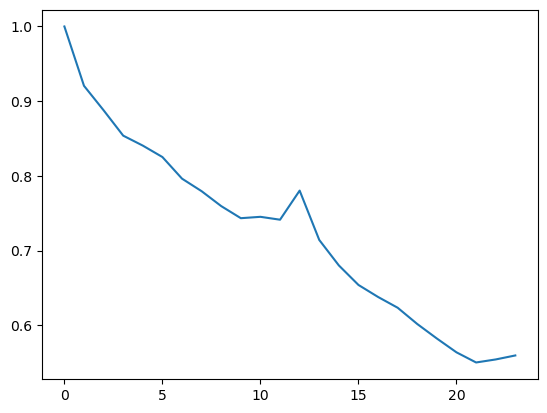

In [81]:
my_acf = acf(df)
plt.plot(my_acf)

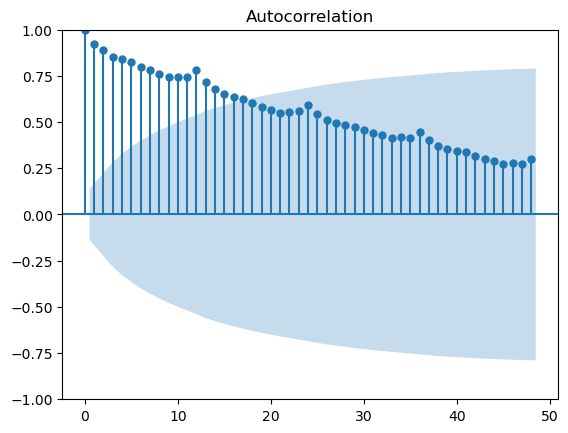

In [ ]:
fig = tsaplots.plot_acf(df, lags=48) # 4 năm

Kết luận: Chuỗi thời gian này không có tính dừng